In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in epg_across_dark_analysis.py next to this notebook
# (run it as a script to regenerate everything: python epg_across_dark_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import epg_across_dark_analysis as ead

plt.rcParams["pdf.fonttype"] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ead.load_session_manager()   # basedir / figure folder / condition: see ead.DEFAULT_*
sess_manager.sess_df.head()

,date,fly,session,closed_loop,rnai,condition,usable,fictrac_dat_file,notes,fly_id
0,06_01_2025,fly1,closed_loop-000,1,0,control,1,fictrac-20250106_102710.dat,NaN,06_01_2025_fly1_condition_control
1,06_01_2025,fly1,dark-001,0,0,control,1,fictrac-20250106_102710.dat,NaN,06_01_2025_fly1_condition_control
2,06_01_2025,fly1,closed_loop-002,2,0,control,1,fictrac-20250106_102710.dat,NaN,06_01_2025_fly1_condition_control
3,06_01_2025,fly2,closed_loop-000,1,0,control,1,fictrac-20250106_112036.dat,NaN,06_01_2025_fly2_condition_control
4,06_01_2025,fly2,dark-001,0,0,control,1,fictrac-20250106_112036.dat,NaN,06_01_2025_fly2_condition_control


In [3]:
sess_manager.fig_folder

PosixPath('/media/mplitt/SSD_storage/fig_scratch/EPG_jGCaMP7f_OctB1RRNAi')

## PVA magnitude

offset mag dark vs closed loop: {'n': 14, 'W': 0.0, 'p': 0.0001220703125}


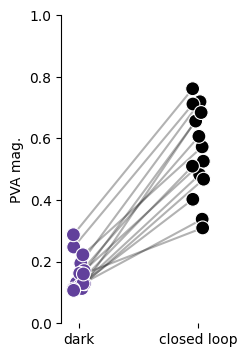

In [4]:
offset_stats = ead.compute_offset_stats(sess_manager)
fig, stats = ead.plot_offset_summary(sess_manager, offset_stats)
print('offset mag dark vs closed loop:', stats)

## Bump-cue offset across closed loop blocks

offset change closed loop 1 vs 2: {'n': 13, 'median_abs_change': 0.21445569993524272}


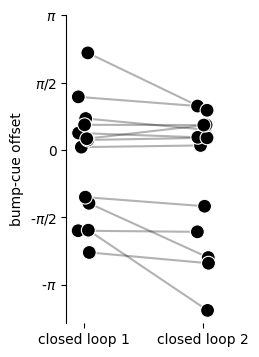

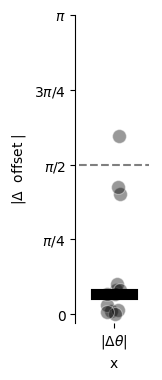

In [5]:
(fig_offsets, fig_change), stats = ead.plot_offset_stability(sess_manager, offset_stats)
print('offset change closed loop 1 vs 2:', stats)

## Attractor dynamics plots

### dPVA vs dHeading

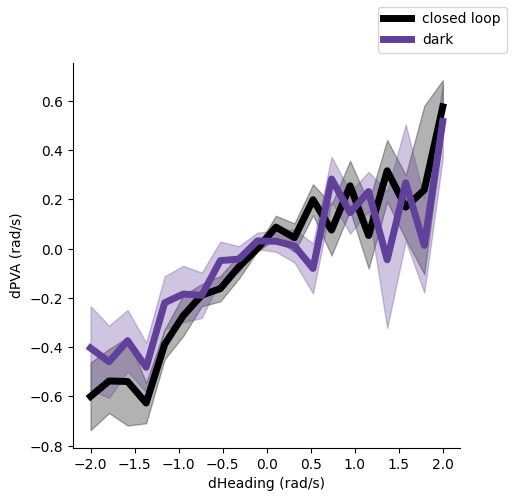

In [6]:
fig, dphi_grouped = ead.plot_dphi_vs_dheading(sess_manager)

### PVA magnitude vs |dHeading|

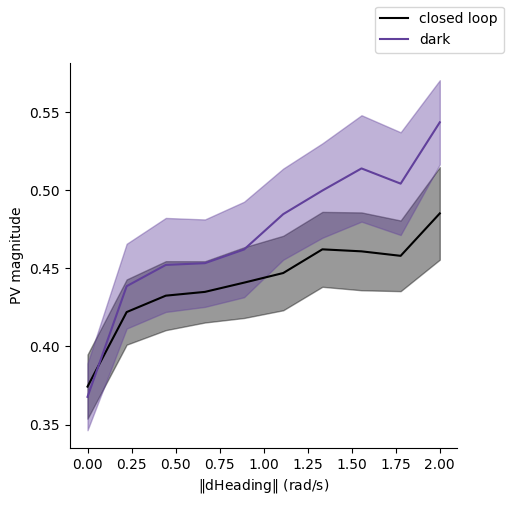

In [7]:
fig, rho_grouped = ead.plot_rho_vs_dheading(sess_manager)

## Bump width comparisons

flies: {'n': 14}


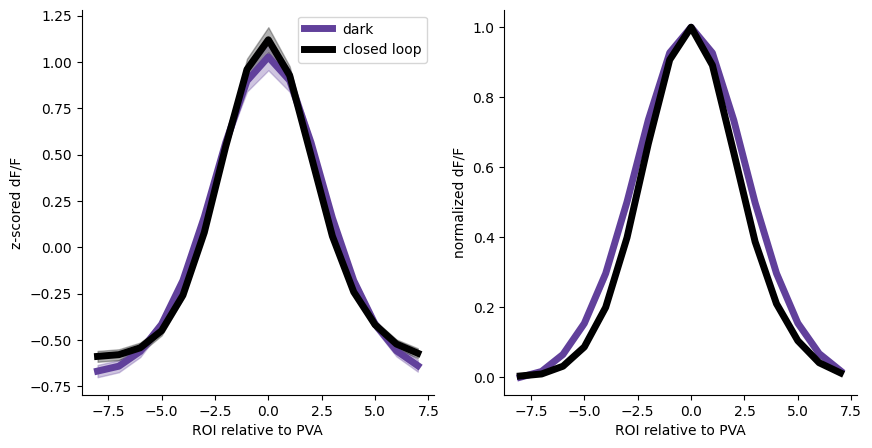

In [8]:
bump_grouped = ead.compute_bump_stats(sess_manager)
fig, stats = ead.plot_bump_profile(sess_manager, bump_grouped)
print('flies:', stats)

bump width dark vs closed loop: {'n': 14, 'W': 1.0, 'p': 0.000244140625}


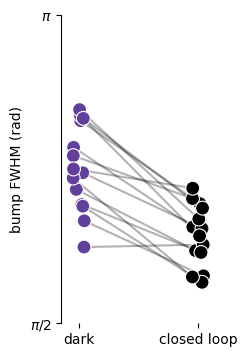

In [9]:
fig, stats = ead.plot_bump_width(sess_manager, bump_grouped)
print('bump width dark vs closed loop:', stats)

## Session heatmaps, offset histograms and polar offset vectors

In [10]:
plotted_flies = ead.plot_session_figures(sess_manager)

Skipping 04_02_2025_fly2_condition_control: missing closed loop 1, dark or closed loop 2
